# Entrega 2 proyecto aprendizaje de máquina

Pedro Pablo Sanín Trujillo (202221527)


## 1 - Carga de datos


In [ ]:
# Importar la librerías del proyecto
import pandas as pd
import tensorflow as tf
from keras.layers import TextVectorization
from sklearn.model_selection import train_test_split

In [ ]:
# En Colab: subir antes datos.zip (clic derecho en el Explorador de VS Code > "Upload to Colab")
# y esta celda lo descomprime. En el computador local no hace nada, porque ./datos ya existe.
import os
import zipfile

if not os.path.isdir("datos") and os.path.exists("datos.zip"):
    zipfile.ZipFile("datos.zip").extractall(".")

print(sorted(os.listdir("datos")))



['50_palabras_mas_comunes', 'eval.csv', 'sample_submission.csv', 'submission_GRU.csv', 'submission_GRU_mejorado.csv', 'submission_LSTM apiladas.csv', 'submission_LSTM apiladas_mejorado.csv', 'submission_LSTM.csv', 'submission_LSTM_mejorado.csv', 'submission_Simple RNN.csv', 'submission_Simple RNN_mejorado.csv', 'submission_Simple RNNs apiladas.csv', 'submission_Simple RNNs apiladas_mejorado.csv', 'submission_XLM-RoBERTa-Twitter.csv', 'submission_XLM-RoBERTa.csv', 'submission_mBERT.csv', 'train.csv']


In [52]:
# A continuación, se cargan los conjuntos de datos de entrenamiento y evaluación

path_train = "./datos/train.csv"
path_eval = "./datos/eval.csv"


dataset_train_original = pd.read_csv(path_train)
dataset_eval_original = pd.read_csv(path_eval)

dataset_train = dataset_train_original.copy()
dataset_eval = dataset_eval_original.copy()

In [53]:
print(
    f"Número de filas y columnas del conjunto de entrenamiento: {dataset_train.shape}"
)

dataset_train.head(10)

Número de filas y columnas del conjunto de entrenamiento: (20466, 3)


,id,text,label
0,0,Lo pedí un martes por internet y llegó al terc...,negativo
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo
2,2,Lo compré hace como dos meses en una tienda de...,neutral
3,3,Le routeur capte très bien dans toute la maiso...,negativo
4,4,"I got it a while back on sale online, it arriv...",neutral
5,5,Comprei esse teclado mês passado pra trabalhar...,positivo
6,6,Comprei há umas duas semanas pela internet e c...,negativo
7,7,"La compre a mediados de año por internet, tard...",positivo
8,8,Les dejo un comentario rápido. Lo pedí a media...,negativo
9,9,The color accuracy on this monitor is genuinel...,positivo


Vemos que el dataset contiene 20466 filas, cada una con un id, la reseña correspondiente y un label que indica que si la reseña es positiva o negativa. Revisando manualmente algunas entradas, confirmamos que los únicos idiomas presentes en las reseñas son español, inglés, portugués, francés y una mezcla de español e inglés. Esto es consistente con lo indicado en el enunciado del proyecto. Preliminarmente, no separaremos los modelos reseñas por idioma pues esto reduce sustancialmente el tamaño de cada conjunto de datos. Sin embargo, si vale la pena identificar el idioma para tener una división train-test balanceada.

Además nuestra métrica de entrenamiento será el accuracy, de acuerdo con la competencia. A continuación, intentaremos identificar el idioma de cada una de nuestras reseñas.


## 2 - Identificando el idioma de la reseña

Para esto, descargaremos las 50 palabras más comunes en cada uno de los idiomas. Por la ley de Zipf, si las listas de las 50 palabras más comunes son distintas, una de las palabras aparecerá en la lista y esto nos servirá para determinar el idioma de la reseña. Asimismo, las palabras más comunes en cada idioma son artículos y generalmente tienen el mismo significado.

Así, el criterio para determinar el idioma de una reseña será el siguiente:

1. El primer y segundo idioma candidato serán los primeros dos conjuntos de palabras que tengan más coincidencia con las palabras de la reseña.

2. Con las palabras que pertenecen al conjunto más común,


In [54]:
import sys
import unicodedata
from collections import Counter

# Tabla de traducción que reemplaza por un espacio todo carácter Unicode de puntuación
# (categorías 'P*'), lo que incluye ¿ ¡ « » “ ” … además de la puntuación ASCII.
puntua = {
    i: " "
    for i in range(sys.maxunicode + 1)
    if unicodedata.category(chr(i)).startswith("P")
}

# Palabras de la lista de inglés que también son muy comunes en español ("lo he usado"),
# por lo que no cuentan como evidencia de inglés dentro de una reseña en español.
AMBIGUAS_EN = {"he"}


def procesar_resena(text):
    """Pasa la reseña a minúsculas, elimina la puntuación y la separa en palabras."""
    text = text.lower()
    text = text.translate(puntua)
    return text.split()


def palabras_exclusivas(palabras_por_idioma):
    """Para cada idioma, las palabras comunes que no aparecen en la lista de ningún otro idioma."""
    return {
        idioma: palabras
        - set().union(
            *(otras for otro, otras in palabras_por_idioma.items() if otro != idioma)
        )
        for idioma, palabras in palabras_por_idioma.items()
    }


def identificar_idioma(resena, palabras_por_idioma, exclusivas):
    """Identifica el idioma de una reseña: 'es', 'en', 'fr', 'pt_br', 'es_en' (bilingüe) o None.

    1. El idioma principal es el que tiene más ocurrencias de sus palabras exclusivas. Si la reseña
       no tiene ninguna palabra exclusiva, se usan todas las palabras comunes (incluidas las compartidas).
    2. Si el idioma principal es español o inglés y la reseña contiene al menos una palabra exclusiva
       del otro idioma, la reseña se considera bilingüe ('es_en').
    """
    conteo = Counter(procesar_resena(resena))

    def puntajes(listas):
        return {
            idioma: sum(n for palabra, n in conteo.items() if palabra in palabras)
            for idioma, palabras in listas.items()
        }

    puntaje = puntajes(exclusivas)
    if max(puntaje.values()) == 0:
        puntaje = puntajes(palabras_por_idioma)
        if max(puntaje.values()) == 0:
            return None
    principal = max(puntaje, key=lambda k: puntaje[k])

    hay_es = any(palabra in exclusivas["es"] for palabra in conteo)
    hay_en = any(palabra in exclusivas["en"] - AMBIGUAS_EN for palabra in conteo)
    if principal in ("es", "en") and hay_es and hay_en:
        return "es_en"
    return principal

In [55]:
# Cargamos las 50 palabras más comunes por idioma y les aplicamos la misma limpieza que a las reseñas,
# para que entradas como "c'", "l'" o "'s" queden como "c", "l" y "s" y puedan coincidir con las reseñas.
path_palabras = "./datos/50_palabras_mas_comunes/50_palabras_mas_comunes.csv"

palabras_comunes = pd.read_csv(path_palabras)
palabras_comunes["palabra"] = palabras_comunes["palabra"].map(
    lambda p: procesar_resena(p)[0]
)

# Conjunto de palabras por idioma, y el subconjunto de palabras exclusivas de cada idioma
palabras_por_idioma = palabras_comunes.groupby("idioma")["palabra"].apply(set).to_dict()
exclusivas = palabras_exclusivas(palabras_por_idioma)

palabras_comunes.head()

,idioma,rank,palabra,frecuencia
0,en,1,you,28787591
1,en,2,i,27086011
2,en,3,the,22761659
3,en,4,to,17099834
4,en,5,a,14484562


In [56]:
print(
    identificar_idioma("Esta es una reseña de prueba", palabras_por_idioma, exclusivas)
)
print(identificar_idioma("This is a test review", palabras_por_idioma, exclusivas))
print(
    identificar_idioma("Ceci est une critique de test", palabras_por_idioma, exclusivas)
)
print(
    identificar_idioma("Esta é uma crítica de teste", palabras_por_idioma, exclusivas)
)
print(
    identificar_idioma(
        "Esta es una reseña de prueba en inglés: This is a test review",
        palabras_por_idioma,
        exclusivas,
    )
)
print(
    identificar_idioma(
        "Esta es una reseña de prueba en francés: Ceci est une critique de test",
        palabras_por_idioma,
        exclusivas,
    )
)

es
en
fr
pt_br
es_en
es


In [57]:
# Identificamos el idioma de cada reseña de entrenamiento y evaluación
dataset_train["idioma"] = dataset_train["text"].map(
    lambda t: identificar_idioma(t, palabras_por_idioma, exclusivas)
)
dataset_eval["idioma"] = dataset_eval["text"].map(
    lambda t: identificar_idioma(t, palabras_por_idioma, exclusivas)
)

dataset_train["idioma"].value_counts(dropna=False, normalize=True)

,proportion
idioma,
es,0.652497
en,0.114678
pt_br,0.114043
fr,0.102511
es_en,0.016271


In [58]:
dataset_train.head()

,id,text,label,idioma
0,0,Lo pedí un martes por internet y llegó al terc...,negativo,es
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo,es
2,2,Lo compré hace como dos meses en una tienda de...,neutral,es
3,3,Le routeur capte très bien dans toute la maiso...,negativo,fr
4,4,"I got it a while back on sale online, it arriv...",neutral,en


Ahora, dividimos el conjunto de datos en prueba y entrenamiento estratificado para incluir una proporción representativa de cada idioma y de cada etiqueta. Para esto, usaremos `sklearn.train_test_split`.


In [59]:
# Codificamos las etiquetas de como enteros
etiquetas = sorted(
    dataset_train["label"].unique()
)  # ['negativo', 'neutral', 'positivo']
etiqueta_a_id = {e: i for i, e in enumerate(etiquetas)}


# División 90/10 estratificada por idioma y etiqueta a la vez: cada combinación
# (p. ej. "fr|neutral") conserva la misma proporción en entrenamiento y prueba.
estrato = dataset_train["idioma"].astype(str) + "|" + dataset_train["label"]

# train_test_split exige al menos 2 reseñas por estrato. Las combinaciones con una sola
# reseña (solo hay una reseña bilingüe es_en neutral) no se pueden dividir, así que van
# directamente a entrenamiento.
raros = estrato.map(estrato.value_counts()) < 2

train_df, test_df = train_test_split(
    dataset_train[~raros],
    test_size=0.1,
    random_state=42,
    stratify=estrato[~raros],
)
train_df = pd.concat([train_df, dataset_train[raros]])


def dataset_a_tf(df, shuffle):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["text"].values, df["label"].map(etiqueta_a_id).values)
    )
    if shuffle:
        ds = ds.shuffle(len(df), seed=42)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)


train_dataset = dataset_a_tf(train_df, shuffle=True)
test_dataset = dataset_a_tf(test_df, shuffle=False)

## 2 - Red neuronal

In [60]:
encoder_mlp = TextVectorization(output_mode="tf_idf")
encoder_mlp.adapt(train_df["text"])

In [61]:
model_mlp = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(), dtype=tf.string),
        encoder_mlp,
    
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3),
    ]
)

model_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_1            │ (None, 19045)          │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       609,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 609,571 (2.33 MB)

 Trainable params: 609,571 (2.33 MB)

 Non-trainable params: 0 (0.00 B)

In [62]:
model_mlp.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"],
)

Ahora para entrenar el modelo, usaremos ``tf.keras.callbacks.EarlyStopping``. Esto nos permite parar el entrenamiento cuando la pérdida de validación (`val_loss`) deja de disminuir, y restaurar los parámetros de la época con menor pérdida de validación. Usamos la pérdida y no el accuracy porque el accuracy de validación puede seguir subiendo levemente mientras el modelo ya se está sobreajustando (la pérdida sube porque el modelo se vuelve demasiado confiado en sus errores).

In [63]:
# En lugar de fijar el número de épocas, entrenamos hasta un máximo de 50 y detenemos el
# entrenamiento cuando la métrica `monitor` de validación deja de mejorar durante `patience`
# épocas seguidas. restore_best_weights=True deja el modelo con los pesos de la mejor época.
# Por defecto se monitorea la pérdida de validación ("val_loss"), que se minimiza; si se pasa
# un accuracy (p. ej. monitor="val_accuracy"), se maximiza.
def entrenar_modelo_con_parada_temprana(
    model, train_dataset, test_dataset, max_epochs=50, patience=3, monitor="val_loss"
):
    modo = "min" if "loss" in monitor else "max"
    parada_temprana = tf.keras.callbacks.EarlyStopping(
        monitor=monitor,
        mode=modo,
        patience=patience,
        restore_best_weights=True,
        verbose=1,  # informa en qué época se detuvo y de qué época restauró los pesos
    )

    history = model.fit(
        train_dataset,
        epochs=max_epochs,
        validation_data=test_dataset,
        callbacks=[parada_temprana],
    )

    # Guardamos en el historial la época cuyos pesos restauró la parada temprana (índice desde 0),
    # para que los resúmenes usen exactamente esa época y no la recalculen con otra métrica.
    history.mejor_epoca = parada_temprana.best_epoch
    print(
        f"Mejor época según {monitor}: {history.mejor_epoca + 1} "
        f"(val_loss = {history.history['val_loss'][history.mejor_epoca]:.4f}, "
        f"val_accuracy = {history.history['val_accuracy'][history.mejor_epoca]:.4f})"
    )

    return history

In [64]:
entrenar_modelo_con_parada_temprana(model_mlp, train_dataset, test_dataset)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.6484 - loss: 0.5956 - val_accuracy: 0.6790 - val_loss: 0.5211
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8015 - loss: 0.3973 - val_accuracy: 0.6888 - val_loss: 0.5579
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8772 - loss: 0.2721 - val_accuracy: 0.6849 - val_loss: 0.6424
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9258 - loss: 0.1778 - val_accuracy: 0.6864 - val_loss: 0.7509
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.
Mejor época según val_loss: 1 (val_loss = 0.5211, val_accuracy = 0.6790)


### 3.1 - Búsqueda de hiperparámetros 

## 3 - Red neuronal recurrente básica


Inicialmente, usaremos una red neuronal recurrente para clasificar las reseñas. Inicialmente, veremos el desempeño de una RNN simple, donde cada neurona tiene información sobre las operaciones que ha hecho en pasos anteriores. Las redes neuronales recurrentes funcionan bien al procesar lenguaje natural pues el lenguaje tiene una naturaleza secuencial.

Usaremos la implementación de RNNs dada por `tf.keras.layers.SimpleRNN`. Para que el texto pueda pasar exitosamente por una red neuronal, debemos vectorizarlo. Para esto, usaremos una capa inicial de la red neuronal dada por `tf.keras.layers.TextVectorization`. Este algoritmo de vectorización combina varias formas de vectorizar frases como _tf_idf_, _count_ (bag of words) y soporta ngramas.


In [65]:
# Para una red recurrente necesitamos una secuencia de índices de palabras (output_mode='int'),
# no un vector tf_idf. Cada reseña se rellena o recorta a 100 palabras (mediana: 57, máximo: 125).


# Tildes a quitar (unicodedata no sirve aquí porque Keras pasa tensores, no str,
# y TensorFlow no trae normalización Unicode sin el paquete tensorflow_text).
TILDES = {
    "[áàâäã]": "a",
    "[éèêë]": "e",
    "[íìîï]": "i",
    "[óòôöõ]": "o",
    "[úùûü]": "u",
    "ñ": "n",
    "ç": "c",
}


def standardize_text(text):
    text = tf.strings.lower(text, encoding="utf-8")
    text = tf.strings.regex_replace(text, "<br />", " ")
    for patron, letra in TILDES.items():
        text = tf.strings.regex_replace(text, patron, letra)
    text = tf.strings.regex_replace(text, "[^a-z']", " ")
    return text


def crear_encoder_rnn(train_df, n_gram=1):

    encoder_rnn = TextVectorization(
        output_mode="int",
        output_sequence_length=100,
        standardize=standardize_text,  ngrams=n_gram  # pyright: ignore[reportArgumentType]
    )
    encoder_rnn.adapt(train_df["text"])
    return encoder_rnn


encoder_rnn = crear_encoder_rnn(train_df)

texto_original = train_df["text"].iloc[0]
texto_vectorizado = encoder_rnn(tf.convert_to_tensor([texto_original]))

encoder_rnn = crear_encoder_rnn(train_df)

texto_original = train_df["text"][1]
texto_vectorizado = encoder_rnn(tf.convert_to_tensor([texto_original]))
print(f"Texto original: {texto_original}")
print(f"Texto vectorizado: {texto_vectorizado}")

Texto original: Les cuento como me fue. Compre esta tablet a mediados de año y llego en cuatro dias a mi casa en Guadalajara, sin ningun problema con el paquete. En mi opinion, la resolucion me resulto ser deficiente para ser honesto. La uso sobre todo por las tardes para revisar correos y ver videos mientras ceno. La pantalla tactil termino siendo muy buena en el uso real.
Texto vectorizado: [[  82  687   69   10  185   18   76 1860    6   70    3  104    9   13
     4   52   12    6   20   24    4  417   42  746  150   19    5   95
     4   20  435    2  530   10   71  107  998   14  107  437    2   23
   147   53   15   36  163   14  732 1686    9  496  938  356 7770    2
   270  570  195  219  172  481    4    5   23  378    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0]]


Ahora, entrenaremos una red neuronal con una capa de embedding, una capa SimpleRNN de 64 neuronas y una capa oculta densa de 32 neuronas con función de activación ReLU. Asimismo, entrenamos un embedding con una dimensión de salida de 64. 


In [66]:
model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(), dtype=tf.string),
        encoder_rnn,
        tf.keras.layers.Embedding(
            input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
        ),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3),
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_3            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,137,539 (4.34 MB)

 Trainable params: 1,137,539 (4.34 MB)

 Non-trainable params: 0 (0.00 B)

In [67]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [68]:
entrenar_modelo_con_parada_temprana(model, train_dataset, test_dataset)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 96s 164ms/step - accuracy: 0.6178 - loss: 0.6799 - val_accuracy: 0.7723 - val_loss: 0.4390
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 94s 164ms/step - accuracy: 0.8374 - loss: 0.3380 - val_accuracy: 0.7611 - val_loss: 0.4362
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 94s 163ms/step - accuracy: 0.9208 - loss: 0.1869 - val_accuracy: 0.7504 - val_loss: 0.5939
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 95s 166ms/step - accuracy: 0.9617 - loss: 0.0972 - val_accuracy: 0.7601 - val_loss: 0.7162
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 95s 164ms/step - accuracy: 0.9769 - loss: 0.0645 - val_accuracy: 0.7577 - val_loss: 0.7665
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.4362, val_accuracy = 0.7611)


### 2.1 - Probando diferentes combinaciones de capas

A continuación, probaremos 5 combinaciones distintas de capas para determinar cual tiene mejor desempeño en validación.

Para no repetir código, definimos una función que arma la red con la misma estructura de la celda anterior
(entrada de texto → `encoder_rnn` → `Embedding` → **capas recurrentes** → `Dense(32, relu)` → `Dense(3)`)
y solo cambia el bloque de capas recurrentes. Cada modelo tiene su propia capa de embedding, de modo que
ninguno comparte pesos entrenables con otro; `encoder_rnn` sí se comparte, pero no tiene pesos entrenables.

In [69]:
def construir_modelo_rnn(capas_recurrentes, nombre):
    """Arma y compila una red recurrente cuyo bloque central son las capas recibidas."""
    model = tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(), dtype=tf.string),
            encoder_rnn,
            tf.keras.layers.Embedding(
                input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
            ),
            *capas_recurrentes,
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(3),
        ],
        name=nombre,
    )
    model.compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(),
        metrics=["accuracy"],
    )
    return model


# Guardamos el historial de entrenamiento de cada combinación para compararlas al final
historiales = {}

#### Modelo 1 - SimpleRNN bidireccional

La misma `SimpleRNN(64)` del modelo base, pero envuelta en `Bidirectional`: una copia lee la reseña de
izquierda a derecha y otra de derecha a izquierda, y sus salidas se concatenan. Así, la representación final
no depende solo de las últimas palabras de la reseña.

In [70]:
model_rnn_1 = construir_modelo_rnn(
    [tf.keras.layers.Bidirectional(tf.keras.layers.SimpleRNN(64))],
    nombre="simplernn_bidireccional",
)
model_rnn_1.summary()

historiales["1 - SimpleRNN bidireccional"] = entrenar_modelo_con_parada_temprana(
    model_rnn_1, train_dataset, test_dataset
)

Model: "simplernn_bidireccional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_3            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,147,843 (4.38 MB)

 Trainable params: 1,147,843 (4.38 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 160s 274ms/step - accuracy: 0.5637 - loss: 0.7415 - val_accuracy: 0.7225 - val_loss: 0.5089
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 158s 274ms/step - accuracy: 0.8190 - loss: 0.3686 - val_accuracy: 0.7831 - val_loss: 0.4416
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 200s 271ms/step - accuracy: 0.9169 - loss: 0.1981 - val_accuracy: 0.7636 - val_loss: 0.5372
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 156s 271ms/step - accuracy: 0.9585 - loss: 0.1047 - val_accuracy: 0.7499 - val_loss: 0.6960
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 157s 272ms/step - accuracy: 0.9741 - loss: 0.0717 - val_accuracy: 0.7650 - val_loss: 0.8099
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.4416, val_accuracy = 0.7831)


#### Modelo 2 - Dos SimpleRNN apiladas

Dos capas `SimpleRNN` apiladas (64 y 32 neuronas). La primera usa `return_sequences=True` para entregarle a la
segunda la salida de cada paso de tiempo, no solo la del último.

In [ ]:
model_rnn_2 = construir_modelo_rnn(
    [
        tf.keras.layers.SimpleRNN(64, return_sequences=True),
        tf.keras.layers.SimpleRNN(32),
    ],
    nombre="simplernn_apiladas",
)
model_rnn_2.summary()

historiales["2 - SimpleRNN apiladas"] = entrenar_modelo_con_parada_temprana(
    model_rnn_2, train_dataset, test_dataset
)

Model: "simplernn_apiladas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_12 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_16 (SimpleRNN)       │ (None, 100, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_17 (SimpleRNN)       │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,139,619 (4.35 MB)

 Trainable params: 1,139,619 (4.35 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.5808 - loss: 0.7447 - val_accuracy: 0.7479 - val_loss: 0.4605
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.8198 - loss: 0.3584 - val_accuracy: 0.7728 - val_loss: 0.4351
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9108 - loss: 0.2063 - val_accuracy: 0.7548 - val_loss: 0.5215
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9531 - loss: 0.1178 - val_accuracy: 0.7611 - val_loss: 0.6266
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9736 - loss: 0.0717 - val_accuracy: 0.7479 - val_loss: 0.7659
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.4351, val_accuracy = 0.7728)


#### Modelo 3 - LSTM

Reemplazamos la `SimpleRNN` por una `LSTM(64)`. Sus compuertas de entrada, olvido y salida le permiten conservar
información a lo largo de secuencias largas y mitigan el desvanecimiento del gradiente de la RNN simple.

In [ ]:
model_rnn_3 = construir_modelo_rnn(
    [tf.keras.layers.LSTM(64)],
    nombre="lstm",
)
model_rnn_3.summary()

historiales["3 - LSTM"] = entrenar_modelo_con_parada_temprana(
    model_rnn_3, train_dataset, test_dataset
)

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_13 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,162,307 (4.43 MB)

 Trainable params: 1,162,307 (4.43 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.6378 - loss: 0.5891 - val_accuracy: 0.7665 - val_loss: 0.4457
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.8279 - loss: 0.3270 - val_accuracy: 0.8163 - val_loss: 0.3236
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.8744 - loss: 0.2425 - val_accuracy: 0.8129 - val_loss: 0.3685
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 14s 25ms/step - accuracy: 0.8973 - loss: 0.1957 - val_accuracy: 0.8188 - val_loss: 0.3653
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.9211 - loss: 0.1509 - val_accuracy: 0.8051 - val_loss: 0.4718
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.3236, val_accuracy = 0.8163)


#### Modelo 4 - GRU bidireccional con dropout

Una `GRU(64)` bidireccional (similar a la LSTM pero con menos parámetros) seguida de un `Dropout(0.5)` para
regularizar, ya que con alrededor de 18.000 reseñas de entrenamiento los modelos se sobreajustan con facilidad.

In [ ]:
model_rnn_4 = construir_modelo_rnn(
    [
        tf.keras.layers.Bidirectional(tf.keras.layers.GRU(64)),
        tf.keras.layers.Dropout(0.5),
    ],
    nombre="gru_bidireccional_dropout",
)
model_rnn_4.summary()

historiales["4 - GRU bidireccional + dropout"] = entrenar_modelo_con_parada_temprana(
    model_rnn_4, train_dataset, test_dataset
)

Model: "gru_bidireccional_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_14 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_11                │ (None, 128)            │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,181,251 (4.51 MB)

 Trainable params: 1,181,251 (4.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 28s 46ms/step - accuracy: 0.6181 - loss: 0.6362 - val_accuracy: 0.7494 - val_loss: 0.4689
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 27s 47ms/step - accuracy: 0.8356 - loss: 0.3248 - val_accuracy: 0.8124 - val_loss: 0.3325
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 28s 49ms/step - accuracy: 0.8909 - loss: 0.2258 - val_accuracy: 0.8158 - val_loss: 0.3944
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 27s 48ms/step - accuracy: 0.9219 - loss: 0.1705 - val_accuracy: 0.8192 - val_loss: 0.4142
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 29s 50ms/step - accuracy: 0.9449 - loss: 0.1247 - val_accuracy: 0.8192 - val_loss: 0.5305
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.3325, val_accuracy = 0.8124)


#### Modelo 5 - Dos LSTM bidireccionales apiladas con dropout

La combinación más profunda: dos `LSTM` bidireccionales apiladas (64 y 32 neuronas), con `Dropout(0.3)` entre ellas
y `Dropout(0.5)` antes de las capas densas.

In [ ]:
model_rnn_5 = construir_modelo_rnn(
    [
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
        tf.keras.layers.Dropout(0.5),
    ],
    nombre="lstm_bidireccionales_apiladas",
)
model_rnn_5.summary()

historiales["5 - LSTM bidireccionales apiladas"] = entrenar_modelo_con_parada_temprana(
    model_rnn_5, train_dataset, test_dataset
)

Model: "lstm_bidireccionales_apiladas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_8            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_15 (Embedding)        │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_12                │ (None, 100, 128)       │        66,048 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_13                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,236,547 (4.72 MB)

 Trainable params: 1,236,547 (4.72 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 52s 85ms/step - accuracy: 0.6093 - loss: 0.6118 - val_accuracy: 0.6575 - val_loss: 0.5294
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 51s 88ms/step - accuracy: 0.6664 - loss: 0.5065 - val_accuracy: 0.7621 - val_loss: 0.4604
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 51s 89ms/step - accuracy: 0.8133 - loss: 0.3513 - val_accuracy: 0.7978 - val_loss: 0.3681
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 50s 87ms/step - accuracy: 0.8689 - loss: 0.2610 - val_accuracy: 0.8075 - val_loss: 0.3969
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 49s 85ms/step - accuracy: 0.8866 - loss: 0.2158 - val_accuracy: 0.7973 - val_loss: 0.4596
Epoch 6/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 50s 87ms/step - accuracy: 0.9091 - loss: 0.1706 - val_accuracy: 0.8002 - val_loss: 0.5447
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.
Mejor época según val_loss: 3 (val_loss = 0.3681, val_accuracy = 0.7978)


#### Creación de archivos submission



In [ ]:
# Métricas de la época que restauró la parada temprana (la de menor val_loss)
resumen_rnn = pd.DataFrame(
    [
        {
            "modelo": nombre,
            "mejor_epoca": h.mejor_epoca + 1,
            "val_loss": h.history["val_loss"][h.mejor_epoca],
            "val_accuracy": h.history["val_accuracy"][h.mejor_epoca],
            "train_accuracy": h.history["accuracy"][h.mejor_epoca],
        }
        for nombre, h in historiales.items()
    ]
).sort_values("val_accuracy", ascending=False)

resumen_rnn

,modelo,mejor_epoca,val_loss,val_accuracy,train_accuracy
2,3 - LSTM,2,0.323592,0.816317,0.827949
3,4 - GRU bidireccional + dropout,2,0.332540,0.812408,0.835605
4,5 - LSTM bidireccionales apiladas,3,0.368050,0.797753,0.813345
1,2 - SimpleRNN apiladas,2,0.435076,0.772838,0.819806
0,1 - SimpleRNN bidireccional,2,0.448385,0.765022,0.847657


In [ ]:
def crear_archivo_predicciones(
    model, df, archivo_salida="./datos/submission.csv", columnas=("text",)
):
    """Predice la etiqueta de cada reseña de `df` y guarda un CSV con el formato de
    ./datos/sample_submission.csv: columnas `id` y `answer` ('negativo', 'neutral' o 'positivo').

    `columnas` son las columnas de `df` que recibe el modelo: con una sola (por defecto "text")
    se le pasan los textos directamente; con varias, un dict {nombre_columna: textos}, que es lo
    que esperan los modelos de dos entradas de la sección 3.2."""
    if len(columnas) == 1:
        entradas = df[columnas[0]].values
    else:
        entradas = {c: df[c].values for c in columnas}
    textos = tf.data.Dataset.from_tensor_slices(entradas).batch(32)

    # El modelo devuelve logits (una fila de 3 valores por reseña): la clase predicha es la de
    # mayor logit, y la traducimos de vuelta a texto con la misma lista usada al codificarlas.
    logits = model.predict(textos)
    clases = logits.argmax(axis=1)

    submission = pd.DataFrame(
        {"id": df["id"].values, "answer": [etiquetas[c] for c in clases]}
    )
    submission.to_csv(archivo_salida, index=False)

    print(f"Archivo guardado en {archivo_salida} ({len(submission)} predicciones)")
    print(submission["answer"].value_counts(normalize=True))
    return submission

In [ ]:
# Cambiar por el modelo con mejor val_accuracy
modelos_rnn = [model_rnn_1, model_rnn_2, model_rnn_3, model_rnn_4, model_rnn_5]
nombres_modelo = ["Simple RNN", "Simple RNNs apiladas","LSTM","GRU","LSTM apiladas"]
modelos_rnn = {"nombre": nombres_modelo, "modelo": modelos_rnn}

for nombre, modelo in zip(modelos_rnn["nombre"], modelos_rnn["modelo"]):
    submission = crear_archivo_predicciones(modelo, dataset_eval, f"./datos/submission_{nombre}.csv")
    submission.head()

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Archivo guardado en ./datos/submission_Simple RNN.csv (6781 predicciones)
answer
positivo    0.536204
negativo    0.269429
neutral     0.194367
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Archivo guardado en ./datos/submission_Simple RNNs apiladas.csv (6781 predicciones)
answer
negativo    0.450229
positivo    0.351423
neutral     0.198348
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Archivo guardado en ./datos/submission_LSTM.csv (6781 predicciones)
answer
positivo    0.454063
negativo    0.356290
neutral     0.189648
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step
Archivo guardado en ./datos/submission_GRU.csv (6781 predicciones)
answer
negativo    0.404070
positivo    0.403333
neutral     0.192597
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step
Archivo guardado en ./datos/submission_LSTM apiladas.csv (6781 predicciones)
answer
nega

### 3.2 - Ajustando y regularizando los modelos RNN

En el proyecto anterior, la última oración era la que más significado daba a la reseña completa. Para esto, agregabamos la última oración como una entrada adicional al modelo. En este caso, haremos lo mismo.

Asimismo, vemos que los modelos que estamos usando tienden al overfitting. Para solucionar esto intentaremos pararemos el entrenamiento en las epochs en función de la función de pérdida y no el accuracy en el entrenamiento. De esta forma, el modelo elegido no se elige de acuerdo a los datos específicos de entrenamiento. 

También, intentaremos regularizar más las RNNs. Para esto, usaremos ``SpatialDropout1D`` después del embedding. A diferencia de ``Dropout``, ``SpatialDropout1D`` hace dropout para columnas enteras del espacio, lo que aumenta la regularización.



In [ ]:
import re

def ultima_oracion(texto):
    """Devuelve la última oración de la reseña (corta después de . ! ?)."""
    oraciones = [o for o in re.split(r"(?<=[.!?])\s+", texto.strip()) if o]
    return oraciones[-1] if oraciones else texto

# .assign crea un DataFrame nuevo y evita el SettingWithCopyWarning
train_df = train_df.assign(ultima=train_df["text"].map(ultima_oracion))
test_df = test_df.assign(ultima=test_df["text"].map(ultima_oracion))
dataset_eval = dataset_eval.assign(ultima=dataset_eval["text"].map(ultima_oracion))


def entradas_modelo(df, columnas):
    """Una columna -> arreglo de textos (como antes); varias -> dict {nombre_columna: textos}."""
    if len(columnas) == 1:
        return df[columnas[0]].values
    return {c: df[c].values for c in columnas}


def dataset_a_tf(df, shuffle, columnas=("text",)):
    ds = tf.data.Dataset.from_tensor_slices(
        (entradas_modelo(df, columnas), df["label"].map(etiqueta_a_id).values)
    )
    if shuffle:
        ds = ds.shuffle(len(df), seed=42)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)


train_dataset = dataset_a_tf(train_df, shuffle=True)
test_dataset = dataset_a_tf(test_df, shuffle=False)



Para comparar de forma justa, cada modelo mejorado conserva exactamente el bloque recurrente de su
modelo original de la sección 2.1. Solo cambian dos cosas:

1. Una segunda entrada con la última oración de la reseña, procesada por su propia copia del bloque recurrente.
2. `SpatialDropout1D(0.3)` después del embedding.

La parada temprana según `val_loss` ya no es una diferencia entre ambos grupos: `entrenar_modelo_con_parada_temprana`
la usa por defecto, así que los modelos originales también se eligen con la pérdida de validación.

In [ ]:
def construir_modelo_rnn_mejorado(
    crear_capas_recurrentes, nombre, tasa_spatial_dropout=0.3
):
    """Igual que `construir_modelo_rnn`, pero con las mejoras de esta sección:

    - Dos entradas: la reseña completa (`text`) y su última oración (`ultima`). Cada una pasa
      por su propia copia del bloque recurrente y las dos salidas se concatenan antes de las
      capas densas.
    - `SpatialDropout1D` justo después del embedding, en ambas ramas.

    `crear_capas_recurrentes` es una función que devuelve una lista NUEVA de capas cada vez que se
    llama, para que cada rama tenga sus propios pesos (si se usaran las mismas capas en las dos
    ramas, Keras compartiría sus pesos). El embedding sí se comparte entre ambas ramas, de modo
    que las palabras de la última oración también aprenden de la reseña completa.
    """
    embedding = tf.keras.layers.Embedding(
        input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
    )

    def rama(entrada):
        x = embedding(encoder_rnn(entrada))
        x = tf.keras.layers.SpatialDropout1D(tasa_spatial_dropout)(x)
        for capa in crear_capas_recurrentes():
            x = capa(x)
        return x

    # Los nombres de los Input coinciden con las columnas del DataFrame (las claves del dict)
    texto = tf.keras.layers.Input(shape=(), dtype=tf.string, name="text")
    ultima = tf.keras.layers.Input(shape=(), dtype=tf.string, name="ultima")

    x = tf.keras.layers.Concatenate()([rama(texto), rama(ultima)])
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    salida = tf.keras.layers.Dense(3)(x)

    model = tf.keras.Model([texto, ultima], salida, name=nombre)
    model.compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(),
        metrics=["accuracy"],
    )
    return model


# Conjuntos de datos con las dos entradas: reseña completa y última oración
columnas_2 = ("text", "ultima")
train_dataset_2 = dataset_a_tf(train_df, shuffle=True, columnas=columnas_2)
test_dataset_2 = dataset_a_tf(test_df, shuffle=False, columnas=columnas_2)

# Usamos las mismas claves que en `historiales` para poder comparar cada modelo con su original
historiales_mejorados = {}

#### Modelo 1 mejorado - SimpleRNN bidireccional

Mismo bloque recurrente que el modelo 1: una `SimpleRNN(64)` bidireccional.

In [ ]:
model_rnn_1_mejorado = construir_modelo_rnn_mejorado(
    lambda: [tf.keras.layers.Bidirectional(tf.keras.layers.SimpleRNN(64))],
    nombre="simplernn_bidireccional_mejorado",
)
model_rnn_1_mejorado.summary()

historiales_mejorados["1 - SimpleRNN bidireccional"] = entrenar_modelo_con_parada_temprana(
    model_rnn_1_mejorado, train_dataset_2, test_dataset_2, monitor="val_loss"
)

Model: "simplernn_bidireccional_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_16        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_8 │ (None, 100, 64)   │          0 │ embedding_16[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_20        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_9 │ (None, 100, 64)   │          0 │ embedding_16[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_21        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_14    │ (None, 128)       │     16,512 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_20[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_15    │ (None, 128)       │     16,512 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_21[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 256)       │          0 │ bidirectional_14… │
│ (Concatenate)       │                   │            │ bidirectional_15… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_38 (Dense)    │ (None, 32)        │      8,224 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_39 (Dense)    │ (None, 3)         │         99 │ dense_38[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,168,451 (4.46 MB)

 Trainable params: 1,168,451 (4.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


/Users/pedropablosanintrujillo/GitHub/proyecto-ml/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


576/576 ━━━━━━━━━━━━━━━━━━━━ 24s 36ms/step - accuracy: 0.6313 - loss: 0.6678 - val_accuracy: 0.7694 - val_loss: 0.4374
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.8182 - loss: 0.3551 - val_accuracy: 0.7640 - val_loss: 0.4282
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.8939 - loss: 0.2414 - val_accuracy: 0.7743 - val_loss: 0.4434
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.9246 - loss: 0.1698 - val_accuracy: 0.7655 - val_loss: 0.5536
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - accuracy: 0.9484 - loss: 0.1240 - val_accuracy: 0.7562 - val_loss: 0.7375
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.4282, val_accuracy = 0.7640)


#### Modelo 2 mejorado - Dos SimpleRNN apiladas

Mismo bloque recurrente que el modelo 2: `SimpleRNN(64, return_sequences=True)` seguida de `SimpleRNN(32)`.

In [ ]:
model_rnn_2_mejorado = construir_modelo_rnn_mejorado(
    lambda: [
        tf.keras.layers.SimpleRNN(64, return_sequences=True),
        tf.keras.layers.SimpleRNN(32),
    ],
    nombre="simplernn_apiladas_mejorado",
)
model_rnn_2_mejorado.summary()

historiales_mejorados["2 - SimpleRNN apiladas"] = entrenar_modelo_con_parada_temprana(
    model_rnn_2_mejorado, train_dataset_2, test_dataset_2, monitor="val_loss"
)

Model: "simplernn_apiladas_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_17        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_17[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_22        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_17[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_23        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_20       │ (None, 100, 64)   │      8,256 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │ not_equal_22[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_22       │ (None, 100, 64)   │      8,256 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │ not_equal_23[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_21       │ (None, 32)        │      3,104 │ simple_rnn_20[0]… │
│ (SimpleRNN)         │                   │            │ not_equal_22[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_23       │ (None, 32)        │      3,104 │ simple_rnn_22[0]… │
│ (SimpleRNN)         │                   │            │ not_equal_23[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 64)        │          0 │ simple_rnn_21[0]… │
│ (Concatenate)       │                   │            │ simple_rnn_23[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_40 (Dense)    │ (None, 32)        │      2,080 │ concatenate_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_41 (Dense)    │ (None, 3)         │         99 │ dense_40[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,152,003 (4.39 MB)

 Trainable params: 1,152,003 (4.39 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.6079 - loss: 0.6940 - val_accuracy: 0.7738 - val_loss: 0.4374
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.8189 - loss: 0.3673 - val_accuracy: 0.7841 - val_loss: 0.4160
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.8855 - loss: 0.2580 - val_accuracy: 0.7767 - val_loss: 0.4725
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9268 - loss: 0.1787 - val_accuracy: 0.7518 - val_loss: 0.5850
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9506 - loss: 0.1258 - val_accuracy: 0.7704 - val_loss: 0.6381
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.4160, val_accuracy = 0.7841)


#### Modelo 3 mejorado - LSTM

Mismo bloque recurrente que el modelo 3: una `LSTM(64)`.

In [ ]:
model_rnn_3_mejorado = construir_modelo_rnn_mejorado(
    lambda: [tf.keras.layers.LSTM(64)],
    nombre="lstm_mejorado",
)
model_rnn_3_mejorado.summary()

historiales_mejorados["3 - LSTM"] = entrenar_modelo_con_parada_temprana(
    model_rnn_3_mejorado, train_dataset_2, test_dataset_2, monitor="val_loss"
)

Model: "lstm_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_18        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_18[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_24        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_18[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_25        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_6 (LSTM)       │ (None, 64)        │     33,024 │ spatial_dropout1… │
│                     │                   │            │ not_equal_24[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_7 (LSTM)       │ (None, 64)        │     33,024 │ spatial_dropout1… │
│                     │                   │            │ not_equal_25[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 128)       │          0 │ lstm_6[0][0],     │
│ (Concatenate)       │                   │            │ lstm_7[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_42 (Dense)    │ (None, 32)        │      4,128 │ concatenate_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_43 (Dense)    │ (None, 3)         │         99 │ dense_42[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,197,379 (4.57 MB)

 Trainable params: 1,197,379 (4.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 24s 39ms/step - accuracy: 0.6862 - loss: 0.5395 - val_accuracy: 0.7924 - val_loss: 0.3815
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 23s 40ms/step - accuracy: 0.8397 - loss: 0.3035 - val_accuracy: 0.8007 - val_loss: 0.3450
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 22s 37ms/step - accuracy: 0.8689 - loss: 0.2520 - val_accuracy: 0.7914 - val_loss: 0.3626
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 21s 37ms/step - accuracy: 0.8903 - loss: 0.2162 - val_accuracy: 0.8021 - val_loss: 0.4503
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 22s 38ms/step - accuracy: 0.9043 - loss: 0.1795 - val_accuracy: 0.7997 - val_loss: 0.4839
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.3450, val_accuracy = 0.8007)


#### Modelo 4 mejorado - GRU bidireccional con dropout

Mismo bloque recurrente que el modelo 4: una `GRU(64)` bidireccional seguida de `Dropout(0.5)`.

In [ ]:
model_rnn_4_mejorado = construir_modelo_rnn_mejorado(
    lambda: [
        tf.keras.layers.Bidirectional(tf.keras.layers.GRU(64)),
        tf.keras.layers.Dropout(0.5),
    ],
    nombre="gru_bidireccional_dropout_mejorado",
)
model_rnn_4_mejorado.summary()

historiales_mejorados["4 - GRU bidireccional + dropout"] = entrenar_modelo_con_parada_temprana(
    model_rnn_4_mejorado, train_dataset_2, test_dataset_2, monitor="val_loss"
)

Model: "gru_bidireccional_dropout_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_19        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_19[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_26        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_19[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_27        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_16    │ (None, 128)       │     49,920 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_26[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_17    │ (None, 128)       │     49,920 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_27[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 128)       │          0 │ bidirectional_16… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128)       │          0 │ bidirectional_17… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 256)       │          0 │ dropout_6[0][0],  │
│ (Concatenate)       │                   │            │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_44 (Dense)    │ (None, 32)        │      8,224 │ concatenate_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_45 (Dense)    │ (None, 3)         │         99 │ dense_44[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,235,267 (4.71 MB)

 Trainable params: 1,235,267 (4.71 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 41s 67ms/step - accuracy: 0.6928 - loss: 0.5626 - val_accuracy: 0.8012 - val_loss: 0.3602
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 42s 73ms/step - accuracy: 0.8451 - loss: 0.2985 - val_accuracy: 0.7978 - val_loss: 0.3487
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 43s 75ms/step - accuracy: 0.8744 - loss: 0.2445 - val_accuracy: 0.8041 - val_loss: 0.3802
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 42s 73ms/step - accuracy: 0.8980 - loss: 0.2015 - val_accuracy: 0.8041 - val_loss: 0.4163
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.9207 - loss: 0.1643 - val_accuracy: 0.8129 - val_loss: 0.4005
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.3487, val_accuracy = 0.7978)


#### Modelo 5 mejorado - Dos LSTM bidireccionales apiladas con dropout

Mismo bloque recurrente que el modelo 5: dos `LSTM` bidireccionales apiladas (64 y 32 neuronas) con `Dropout(0.3)` entre ellas y `Dropout(0.5)` al final.

In [ ]:
model_rnn_5_mejorado = construir_modelo_rnn_mejorado(
    lambda: [
        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(64, return_sequences=True)
        ),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
        tf.keras.layers.Dropout(0.5),
    ],
    nombre="lstm_bidireccionales_apiladas_mejorado",
)
model_rnn_5_mejorado.summary()

historiales_mejorados["5 - LSTM bidireccionales apiladas"] = entrenar_modelo_con_parada_temprana(
    model_rnn_5_mejorado, train_dataset_2, test_dataset_2, monitor="val_loss"
)

Model: "lstm_bidireccionales_apiladas_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_20        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_20[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_28        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 100, 64)   │          0 │ embedding_20[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_29        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_18    │ (None, 100, 128)  │     66,048 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_28[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_20    │ (None, 100, 128)  │     66,048 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_29[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 100, 128)  │          0 │ bidirectional_18… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 100, 128)  │          0 │ bidirectional_20… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_19    │ (None, 64)        │     41,216 │ dropout_8[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal_28[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_21    │ (None, 64)        │     41,216 │ dropout_10[0][0], │
│ (Bidirectional)     │                   │            │ not_equal_29[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 64)        │          0 │ bidirectional_19… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 64)        │          0 │ bidirectional_21… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 128)       │          0 │ dropout_9[0][0],  │
│ (Concatenate)       │                   │            │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_46 (Dense)    │ (None, 32)        │      4,128 │ concatenate_8[0]… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,345,859 (5.13 MB)

 Trainable params: 1,345,859 (5.13 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 78s 125ms/step - accuracy: 0.6852 - loss: 0.5395 - val_accuracy: 0.7811 - val_loss: 0.3572
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 77s 133ms/step - accuracy: 0.8340 - loss: 0.3177 - val_accuracy: 0.7948 - val_loss: 0.3515
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 78s 136ms/step - accuracy: 0.8636 - loss: 0.2594 - val_accuracy: 0.7963 - val_loss: 0.3874
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 78s 135ms/step - accuracy: 0.8830 - loss: 0.2253 - val_accuracy: 0.7934 - val_loss: 0.4246
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 78s 135ms/step - accuracy: 0.8919 - loss: 0.2066 - val_accuracy: 0.7909 - val_loss: 0.4880
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor época según val_loss: 2 (val_loss = 0.3515, val_accuracy = 0.7948)


#### Comparación con los modelos originales

Para cada modelo tomamos las métricas de la época que restauró la parada temprana. Tanto en los originales como
en los mejorados esa época se eligió con `val_loss`, así que el `val_accuracy` reportado no está sesgado por la
selección y ambos grupos se comparan en igualdad de condiciones. Con ~2.000 reseñas de validación, el error estándar
del accuracy es de casi 1 punto, así que diferencias menores a eso no son concluyentes.

In [ ]:
def resumir_historiales(historiales):
    """Una fila por modelo con las métricas de la época restaurada por la parada temprana."""
    filas = []
    for nombre, h in historiales.items():
        mejor = h.mejor_epoca
        filas.append(
            {
                "modelo": nombre,
                "mejor_epoca": mejor + 1,
                "val_accuracy": h.history["val_accuracy"][mejor],
                "val_loss": h.history["val_loss"][mejor],
                "train_accuracy": h.history["accuracy"][mejor],
            }
        )
    return pd.DataFrame(filas)


comparacion = resumir_historiales(historiales).merge(
    resumir_historiales(historiales_mejorados),
    on="modelo",
    suffixes=("_original", "_mejorado"),
)
comparacion["diferencia_val_accuracy"] = (
    comparacion["val_accuracy_mejorado"] - comparacion["val_accuracy_original"]
)

comparacion[
    [
        "modelo",
        "mejor_epoca_original",
        "mejor_epoca_mejorado",
        "val_loss_original",
        "val_loss_mejorado",
        "val_accuracy_original",
        "val_accuracy_mejorado",
        "diferencia_val_accuracy",
        "train_accuracy_original",
        "train_accuracy_mejorado",
    ]
].sort_values("val_accuracy_mejorado", ascending=False)

,modelo,mejor_epoca_original,mejor_epoca_mejorado,val_loss_original,val_loss_mejorado,val_accuracy_original,val_accuracy_mejorado,diferencia_val_accuracy,train_accuracy_original,train_accuracy_mejorado
2,3 - LSTM,2,2,0.323592,0.345020,0.816317,0.800684,-0.015633,0.827949,0.839676
3,4 - GRU bidireccional + dropout,2,2,0.332540,0.348663,0.812408,0.797753,-0.014656,0.835605,0.845106
4,5 - LSTM bidireccionales apiladas,3,2,0.368050,0.351484,0.797753,0.794822,-0.002931,0.813345,0.834030
1,2 - SimpleRNN apiladas,2,2,0.435076,0.415954,0.772838,0.784074,0.011236,0.819806,0.818883
0,1 - SimpleRNN bidireccional,2,2,0.448385,0.428196,0.765022,0.764045,-0.000977,0.847657,0.818231


In [ ]:
# Archivos submission de los modelos mejorados (reciben la reseña y su última oración)
modelos_mejorados = {
    "Simple RNN": model_rnn_1_mejorado,
    "Simple RNNs apiladas": model_rnn_2_mejorado,
    "LSTM": model_rnn_3_mejorado,
    "GRU": model_rnn_4_mejorado,
    "LSTM apiladas": model_rnn_5_mejorado,
}

for nombre, modelo in modelos_mejorados.items():
    crear_archivo_predicciones(
        modelo,
        dataset_eval,
        f"./datos/submission_{nombre}_mejorado.csv",
        columnas=columnas_2,
    )

212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Archivo guardado en ./datos/submission_Simple RNN_mejorado.csv (6781 predicciones)
answer
positivo    0.494470
negativo    0.310869
neutral     0.194662
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
Archivo guardado en ./datos/submission_Simple RNNs apiladas_mejorado.csv (6781 predicciones)
answer
negativo    0.484589
positivo    0.314703
neutral     0.200708
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step
Archivo guardado en ./datos/submission_LSTM_mejorado.csv (6781 predicciones)
answer
negativo    0.482230
positivo    0.328123
neutral     0.189648
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step
Archivo guardado en ./datos/submission_GRU_mejorado.csv (6781 predicciones)
answer
negativo    0.452441
positivo    0.355552
neutral     0.192007
Name: proportion, dtype: float64
212/212 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step
Archivo guardado en ./datos/submission_LSTM apilada

Vemos entonces que estas estrategias de regularización no funcionaron.

### 3.3 - Identificación del error

Para entender en qué se equivocan las RNN, analizamos sobre `test_df` el modelo con mejor `val_accuracy` de las
secciones 3.1 y 3.2:

1. Precisión, recall y F1 de cada clase.
2. La matriz de confusión normalizada por fila: qué fracción de las reseñas de cada clase real termina en cada
   clase predicha.
3. El accuracy por idioma, usando la columna `idioma` de la sección 2.
4. Una muestra de reseñas mal clasificadas, para leerlas completas.

`identificar_errores` solo recibe las clases predichas, así que la reutilizamos tal cual con mBERT en la sección 4.

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report


def identificar_errores(clases, df, nombre, n_ejemplos=10):
    """Analiza las predicciones `clases` (0, 1 o 2) sobre `df` y devuelve las reseñas mal clasificadas."""
    reales = df["label"].map(etiqueta_a_id).values

    print(classification_report(reales, clases, target_names=etiquetas, digits=3))

    ConfusionMatrixDisplay.from_predictions(
        reales,
        clases,
        display_labels=etiquetas,
        normalize="true",  # cada fila suma 1
        values_format=".2f",
        cmap="Blues",
    )
    plt.title(f"Matriz de confusión - {nombre}")
    plt.xlabel("Clase predicha")
    plt.ylabel("Clase real")
    plt.show()

    resultados = df.assign(
        idioma=df["idioma"].astype(str),
        prediccion=[etiquetas[c] for c in clases],
        acierto=clases == reales,
    )
    display(
        resultados.groupby("idioma")["acierto"]
        .agg(accuracy="mean", resenas="size")
        .sort_values("accuracy")
    )

    errores = resultados.loc[
        ~resultados["acierto"], ["idioma", "label", "prediccion", "text"]
    ]
    print(f"{len(errores)} de {len(df)} reseñas mal clasificadas. Algunas de ellas:")
    with pd.option_context("display.max_colwidth", None):
        display(errores.sample(min(n_ejemplos, len(errores)), random_state=42))
    return errores

In [ ]:
# Cada RNN con su historial y las columnas que recibe (las mejoradas también reciben la última oración)
candidatos = [
    (nombre, historial, modelo, ("text",))
    for (nombre, historial), modelo in zip(
        historiales.items(),
        [model_rnn_1, model_rnn_2, model_rnn_3, model_rnn_4, model_rnn_5],
    )
] + [
    (f"{nombre} (mejorado)", historial, modelo, columnas_2)
    for (nombre, historial), modelo in zip(
        historiales_mejorados.items(),
        [
            model_rnn_1_mejorado,
            model_rnn_2_mejorado,
            model_rnn_3_mejorado,
            model_rnn_4_mejorado,
            model_rnn_5_mejorado,
        ],
    )
]

# La de mejor val_accuracy en la época que restauró la parada temprana
nombre_rnn, _, modelo_rnn, columnas_rnn = max(
    candidatos, key=lambda c: c[1].history["val_accuracy"][c[1].mejor_epoca]
)
print(f"Mejor RNN: {nombre_rnn}")

lotes = tf.data.Dataset.from_tensor_slices(entradas_modelo(test_df, columnas_rnn)).batch(32)
clases_rnn = modelo_rnn.predict(lotes).argmax(axis=1)

errores_rnn = identificar_errores(clases_rnn, test_df, nombre_rnn)

## 4 - Transformers

Para usar transformers, usaremos PyTorch pues este puede usar GPU para correr modelos preentrenados. Comparamos tres
modelos multilingües de 12 capas que entienden las reseñas en español, inglés, francés y portugués (incluidas las
bilingües) sin tener que separarlas por idioma:

| Sección | Modelo | Preentrenamiento |
|---|---|---|
| 4.1 | `bert-base-multilingual-cased` (mBERT) | Wikipedia en 104 idiomas |
| 4.2 | `xlm-roberta-base` (XLM-RoBERTa) | 2,5 TB de texto de CommonCrawl en 100 idiomas |
| 4.3 | `cardiffnlp/twitter-xlm-roberta-base-sentiment` | XLM-RoBERTa con tuits, ya ajustado para clasificar sentimiento |

A diferencia de las RNN, un transformer lee la reseña completa a la vez con autoatención: cada palabra mira a todas
las demás. Por eso puede captar por sí solo que la intención de la reseña suele estar en la última oración ("A fin de
cuentas, el rendimiento luce ordinario"), sin darle esa oración como entrada aparte como en la sección 3.2.

Hacemos *fine-tuning*: sobre la salida del primer token se agrega una capa lineal de 3 salidas (negativo, neutral,
positivo) y se reentrena toda la red con una tasa de aprendizaje baja. Todo el código es común a los tres modelos:
para probar otro modelo de Hugging Face basta con pasar su nombre a `entrenar_transformer`.

**GPU en macOS y Windows.** El código elige solo el dispositivo disponible: `cuda` (GPU NVIDIA en Windows/Linux),
`mps` (GPU de Apple Silicon en macOS) o `cpu` si no hay GPU. En Windows, `pip install torch` instala por defecto la
versión **sin** CUDA: para usar la GPU hay que instalar PyTorch con el comando que indica
https://pytorch.org/get-started/locally/ (opción *CUDA*).

In [31]:
# Instala transformers en el kernel activo (igual en macOS, Windows y Colab).
# sentencepiece lo necesita el tokenizador del modelo de Twitter (sección 4.3).
%pip install -q transformers sentencepiece

ERROR:tensorflow:==================================
Object was never used (type <class 'tensorflow.python.ops.tensor_array_ops.TensorArray'>):
If you want to mark it as used call its "mark_used()" method.
It was originally created here:
  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/ops/map_fn.py", line 496, in map_fn
    _, r_a = while_loop.while_loop(  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/ops/while_loop.py", line 487, in while_loop
    while cond(*loop_vars):  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/ops/while_loop.py", line 479, in <lambda>
    body = lambda i, lv: (i + 1, orig_body(*lv))  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/ops/map_fn.py", line 494, in compute
    return (i + 1, tas)  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/util/tf_should_use.py", line 288, in wrapped
    return _add_should_use_warning(fn(*args, **kwargs),


In [32]:
import gc
import os

# En macOS, las operaciones que MPS aún no soporta se ejecutan en CPU en vez de lanzar un error.
# Debe definirse antes de importar torch.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

from types import SimpleNamespace

import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)


def elegir_dispositivo():
    """GPU NVIDIA (Windows/Linux) -> GPU Apple (macOS) -> CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def liberar_memoria_gpu():
    """Devuelve al sistema la memoria de la GPU que PyTorch tenía reservada y ya no usa."""
    gc.collect()
    if dispositivo.type == "cuda":
        torch.cuda.empty_cache()
    elif dispositivo.type == "mps":
        torch.mps.empty_cache()


dispositivo = elegir_dispositivo()
torch.manual_seed(42)
print(f"Dispositivo: {dispositivo}")

Dispositivo: cuda


Reutilizamos la misma división estratificada `train_df` / `test_df` y la misma codificación de etiquetas
`etiqueta_a_id` de las secciones anteriores, para que los resultados sean comparables.

- `cargar_transformer` descarga de Hugging Face el tokenizador y el modelo, con una capa de clasificación de 3 clases.
  Si el modelo no la trae (o trae una con otro número de clases), se crea nueva y aparece un aviso de pesos
  `classifier` *MISSING* o *MISMATCHED*, que es esperado.
- `dataset_a_torch` es el equivalente de `dataset_a_tf`: tokeniza cada lote con el tokenizador del modelo y lo
  rellena solo hasta la reseña más larga del lote. Cada modelo tiene su propio vocabulario, por eso el tokenizador se
  pasa como argumento. La reseña más larga del conjunto tiene 195 tokens con el tokenizador de mBERT, así que
  `max_length=256` no recorta ninguna.

In [33]:
MAX_TOKENS = 256


def cargar_transformer(nombre_modelo):
    """Tokenizador y modelo `nombre_modelo` de Hugging Face, con una capa de clasificación de 3 clases."""
    tokenizador = AutoTokenizer.from_pretrained(nombre_modelo)
    torch.manual_seed(42)  # la capa nueva se inicializa igual en cada ejecución
    model = AutoModelForSequenceClassification.from_pretrained(
        nombre_modelo,
        num_labels=len(etiquetas),
        id2label=dict(enumerate(etiquetas)),
        label2id=etiqueta_a_id,
        # Si el modelo trae una capa de clasificación con otro número de clases, se reemplaza por una nueva
        ignore_mismatched_sizes=True,
    ).to(dispositivo)
    print(f"{nombre_modelo}: {sum(p.numel() for p in model.parameters()):,} parámetros")
    return tokenizador, model


def tokenizar(textos, tokenizador):
    return tokenizador(
        list(textos),
        padding=True,
        truncation=True,
        max_length=MAX_TOKENS,
        return_tensors="pt",
    )


def dataset_a_torch(df, shuffle, tokenizador, batch_size=16):
    """Lotes de reseñas tokenizadas con su etiqueta en `labels`."""
    ejemplos = list(zip(df["text"], df["label"].map(etiqueta_a_id)))

    def armar_lote(lote):
        textos, ids = zip(*lote)
        entradas = tokenizar(textos, tokenizador)
        entradas["labels"] = torch.tensor(ids)
        return entradas

    # num_workers=0 (valor por defecto): los procesos auxiliares del DataLoader fallan
    # dentro de notebooks en Windows y macOS, así que tokenizamos en el proceso principal.
    return DataLoader(
        ejemplos, batch_size=batch_size, shuffle=shuffle, collate_fn=armar_lote
    )

El entrenamiento sigue la misma lógica que `entrenar_modelo_con_parada_temprana`: se detiene cuando `val_loss` deja
de mejorar durante `patience` épocas y restaura los pesos de la mejor época. Devuelve un objeto con los mismos
atributos que el `History` de Keras (`history` y `mejor_epoca`), para reutilizar `resumir_historiales`.

Los transformers ya vienen preentrenados, así que bastan pocas épocas: usamos `AdamW` con tasa de aprendizaje `2e-5`,
que sube durante el primer 10 % de los pasos y luego baja linealmente a 0. Con tasas más altas el *fine-tuning* tiende
a borrar lo aprendido en el preentrenamiento.

In [34]:
@torch.no_grad()
def evaluar_transformer(model, loader):
    """Pérdida y accuracy promedio del modelo sobre `loader`."""
    model.eval()
    perdida, aciertos, n = 0.0, 0, 0
    for lote in loader:
        lote = lote.to(dispositivo)
        salida = model(**lote)
        perdida += salida.loss.item() * len(lote["labels"])
        aciertos += (salida.logits.argmax(dim=-1) == lote["labels"]).sum().item()
        n += len(lote["labels"])
    return perdida / n, aciertos / n


def entrenar_transformer_con_parada_temprana(
    model, train_loader, test_loader, max_epochs=4, patience=1, lr=2e-5
):
    optimizador = torch.optim.AdamW(model.parameters(), lr=lr)
    pasos = max_epochs * len(train_loader)
    planificador = get_linear_schedule_with_warmup(optimizador, int(0.1 * pasos), pasos)

    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    mejor_epoca, mejor_estado = 0, None

    for epoca in range(max_epochs):
        model.train()
        perdida, aciertos, n = 0.0, 0, 0
        for lote in tqdm(train_loader, desc=f"Época {epoca + 1}/{max_epochs}"):
            lote = lote.to(dispositivo)
            salida = model(**lote)  # con `labels`, el modelo calcula la entropía cruzada
            salida.loss.backward()
            optimizador.step()
            planificador.step()
            optimizador.zero_grad()

            perdida += salida.loss.item() * len(lote["labels"])
            aciertos += (salida.logits.argmax(dim=-1) == lote["labels"]).sum().item()
            n += len(lote["labels"])

        val_loss, val_accuracy = evaluar_transformer(model, test_loader)
        for clave, valor in zip(
            history, (perdida / n, aciertos / n, val_loss, val_accuracy)
        ):
            history[clave].append(valor)
        print(
            f"loss = {perdida / n:.4f}, accuracy = {aciertos / n:.4f}, "
            f"val_loss = {val_loss:.4f}, val_accuracy = {val_accuracy:.4f}"
        )

        if val_loss <= min(history["val_loss"]):
            # Copia de los pesos en CPU, equivalente a restore_best_weights=True
            mejor_epoca = epoca
            mejor_estado = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
        elif epoca - mejor_epoca >= patience:
            print(f"Parada temprana en la época {epoca + 1}")
            break

    model.load_state_dict(mejor_estado)
    print(
        f"Mejor época según val_loss: {mejor_epoca + 1} "
        f"(val_loss = {history['val_loss'][mejor_epoca]:.4f}, "
        f"val_accuracy = {history['val_accuracy'][mejor_epoca]:.4f})"
    )
    return SimpleNamespace(history=history, mejor_epoca=mejor_epoca)

`entrenar_transformer` junta todos los pasos para un modelo: lo carga, lo entrena, crea su archivo submission y
predice las clases de `test_df` para la identificación del error. Para el archivo de predicciones reutilizamos
`crear_archivo_predicciones`, que llama a `model.predict` como en Keras: `PredictorTransformer` envuelve al modelo de
PyTorch con ese mismo método. Al terminar, el modelo pasa a la CPU para dejar la GPU libre para el siguiente.

In [ ]:
class PredictorTransformer:
    """Adaptador con el `predict` de Keras: recibe los lotes de textos de tf.data que arma
    `crear_archivo_predicciones` y devuelve los logits como arreglo de NumPy."""

    def __init__(self, model, tokenizador):
        self.model = model
        self.tokenizador = tokenizador

    @torch.no_grad()
    def predict(self, lotes):
        self.model.eval()
        logits = []
        for lote in lotes:
            textos = [t.decode("utf-8") for t in lote.numpy()]
            entradas = tokenizar(textos, self.tokenizador).to(dispositivo)
            logits.append(self.model(**entradas).logits.cpu())
        return torch.cat(logits).numpy()


def entrenar_transformer(nombre_modelo, nombre_corto, **parametros_entrenamiento):
    """Carga, entrena y evalúa el transformer `nombre_modelo` de Hugging Face.

    `parametros_entrenamiento` (p. ej. lr=1e-5 o max_epochs=3) se pasan a
    `entrenar_transformer_con_parada_temprana`. El modelo devuelto queda en la CPU: para volver
    a usarlo, hay que moverlo con `.to(dispositivo)`."""
    tokenizador, model = cargar_transformer(nombre_modelo)
    historial = entrenar_transformer_con_parada_temprana(
        model,
        dataset_a_torch(train_df, shuffle=True, tokenizador=tokenizador),
        dataset_a_torch(test_df, shuffle=False, tokenizador=tokenizador),
        **parametros_entrenamiento,
    )

    predictor = PredictorTransformer(model, tokenizador)
    crear_archivo_predicciones(
        predictor, dataset_eval, f"./datos/submission_{nombre_corto}.csv"
    )

    # Clases predichas en test_df, para la identificación del error
    lotes_test = tf.data.Dataset.from_tensor_slices(test_df["text"].values).batch(32)
    clases_test = predictor.predict(lotes_test).argmax(axis=1)

    model.to("cpu")
    liberar_memoria_gpu()
    return SimpleNamespace(
        model=model, tokenizador=tokenizador, historial=historial, clases_test=clases_test
    )

### 4.1 - BERT multilingüe (mBERT)

`bert-base-multilingual-cased` es un BERT preentrenado con Wikipedia en 104 idiomas. Es nuestra referencia: los otros
dos modelos tienen la misma profundidad (12 capas), así que sus diferencias con mBERT vienen del preentrenamiento y
no de la arquitectura.

In [38]:
mbert = entrenar_transformer("bert-base-multilingual-cased", "mBERT")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


bert-base-multilingual-cased: 177,855,747 parámetros


Época 1/4: 100%|██████████| 1152/1152 [07:49<00:00,  2.45it/s]


loss = 0.4888, accuracy = 0.7450, val_loss = 0.2950, val_accuracy = 0.8588


Época 2/4: 100%|██████████| 1152/1152 [07:48<00:00,  2.46it/s]


loss = 0.2422, accuracy = 0.8710, val_loss = 0.2324, val_accuracy = 0.8798


Época 3/4: 100%|██████████| 1152/1152 [07:49<00:00,  2.45it/s]


loss = 0.1714, accuracy = 0.9074, val_loss = 0.2317, val_accuracy = 0.8813


Época 4/4: 100%|██████████| 1152/1152 [07:48<00:00,  2.46it/s]


loss = 0.1268, accuracy = 0.9337, val_loss = 0.2409, val_accuracy = 0.8852
Parada temprana en la época 4
Mejor época según val_loss: 3 (val_loss = 0.2317, val_accuracy = 0.8813)
Archivo guardado en ./datos/submission_mBERT.csv (6781 predicciones)
answer
positivo    0.434744
negativo    0.373544
neutral     0.191712
Name: proportion, dtype: float64


In [ ]:
print(open("./datos/submission_mBERT.csv").read())


id,answer
0,negativo
1,neutral
2,positivo
3,neutral
4,negativo
5,positivo
6,negativo
7,positivo
8,negativo
9,negativo
10,neutral
11,negativo
12,negativo
13,positivo
14,positivo
15,negativo
16,positivo
17,negativo
18,negativo
19,negativo
20,neutral
21,positivo
22,neutral
23,negativo
24,negativo
25,negativo
26,positivo
27,neutral
28,negativo
29,negativo
30,positivo
31,positivo
32,positivo
33,neutral
34,negativo
35,negativo
36,negativo
37,positivo
38,positivo
39,negativo
40,positivo
41,positivo
42,neutral
43,negativo
44,negativo
45,positivo
46,neutral
47,negativo
48,positivo
49,negativo
50,positivo
51,positivo
52,positivo
53,negativo
54,negativo
55,neutral
56,neutral
57,positivo
58,negativo
59,negativo
60,negativo
61,negativo
62,neutral
63,positivo
64,negativo
65,positivo
66,positivo
67,negativo
68,negativo
69,negativo
70,positivo
71,negativo
72,negativo
73,positivo
74,neutral
75,negativo
76,negativo
77,negativo
78,neutral
79,positivo
80,positivo
81,neutral
82,neutral
83,neutral
84,positi

#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.

              precision    recall  f1-score   support

    negativo      0.843     0.827     0.834       738
     neutral      0.998     1.000     0.999       560
    positivo      0.832     0.846     0.839       749

    accuracy                          0.881      2047
   macro avg      0.891     0.891     0.891      2047
weighted avg      0.881     0.881     0.881      2047



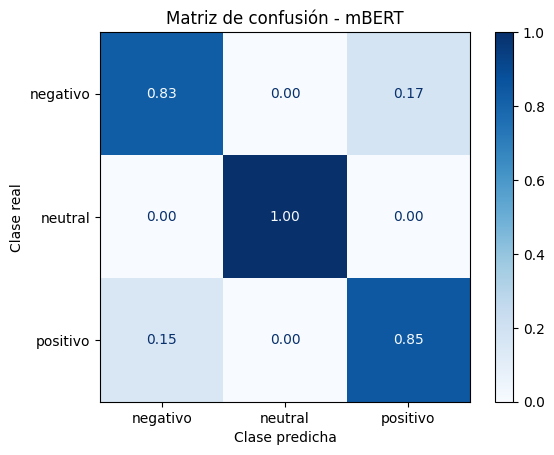

,accuracy,resenas
idioma,,
fr,0.814286,210
en,0.837607,234
pt_br,0.866953,233
es_en,0.878788,33
es,0.902019,1337


243 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
9903,es,positivo,negativo,"Lo compré hace un par de semanas y lo estoy usando en casa casi todos los días, nada del otro mundo todavía. Me alegra haber elegido la conexión, la verdad. Eso sí, el envío no vale lo que cuesta, tardó y pagué bastante. En fin, ni fu ni fa."
10470,es,negativo,positivo,"Me llego el teclado el martes por la tarde, dos dias despues de pedirlo, en una caja normal de envio. Lo uso conectado a la compu del escritorio, sobre todo para trabajar en las noches. El teclado esta muy por debajo de la media. Por otro lado, el menu de ajustes vale totalmente la pena. Ahi lo dejo, no se, cada quien sabra."
2297,en,negativo,positivo,"Bought this bluetooth speaker for my kitchen last month because my old one died mid-pancake recipe. My daughter uses it for homework music too. I actually returned it once, the first unit had a loose charging port, but the replacement has been just as bad. My husband took it to the garage, came back for it, I ended up buying a second one for him. Honestly, not using it anymore, it just sits there."
2456,es,positivo,negativo,"Compré esto en línea a mediados de mes y me llegó como en cuatro días. El tamaño es justo lo que estaba buscando, lo ocupó mi hermana un rato cuando vino de visita y le pareció de buen tamaño también. La comodidad se dañó antes de lo que esperaba, y eso que apenas lo traía de la caja."
4839,es,positivo,negativo,"Lo pedí hace un par de semanas cuando estaba en oferta, llegó a mi casa en unos cinco días. La construcción está muy por debajo de la media, la he estado usando en la sala casi a diario. Por cierto, me encantó el control remoto de principio a fin, lo manejo desde el sillón sin problema. Lo dejo a tu criterio."
9901,es,negativo,positivo,"Lo compré hace poco y lo estoy usando en casa casi a diario. El sonido fue todo un acierto, de hecho. Lo que sí me arrepiento es de haber elegido el manual de uso en vez de otra opción. Sigo con dudas, la verdad."
16800,fr,negativo,positivo,"Le blender broie la glace et les fruits congelés sans effort, et le bol est assez grand pour toute la famille. Par contre, le moteur siffle fort le matin et la base glisse sur le comptoir quand je monte la vitesse. Le nettoyage se fait vite, mais le joint du couvercle retient des résidus. Chaque usage me confirme un côté, puis l'autre me déçoit. Je ne sais toujours pas si je le garderais à long terme."
2358,es,negativo,positivo,"Las zapatillas tienen un amortiguado que de verdad absorbe bien los impactos en pavimento, mis rodillas lo agradecieron desde la primera salida. Ahora bien, la malla del upper transpira poco y a mitad de recorrido ya sentía el pie caliente. La suela agarra decente en seco, aunque en mojado dudo. Sí sirven para distancias cortas, para tiradas largas no me queda claro si aguantarían el ritmo. Tendré que seguir probándolas para decidir si me quedo con ellas."
9835,es,positivo,negativo,"Compré este equipo a mediados de mes y llegó en tres días a mi casa. El procesador fue todo un acierto, la verdad que sin quejas en esa parte. Ahora, el cargador me decepcionó de lo lindo; no me lo esperaba. Lo estuve probando estos días junto con todo lo demás que venía en la caja."
20310,es,positivo,negativo,"El parlante bluetooth suena bastante bien en volúmenes medios, los graves sorprenden para el tamaño que tiene. Lo que no me termina de convencer es la batería: prometen horas y en mi uso diario rinde bastante menos de lo esperado. La conexión a veces se corta cerca de la cocina, otras veces ni un salto. No sé si es un buen comprador para el precio que pagué, me quedo con la duda todavía."


In [42]:
errores_mbert = identificar_errores(mbert.clases_test, test_df, "mBERT")

### 4.2 - XLM-RoBERTa

`xlm-roberta-base` es un RoBERTa multilingüe preentrenado con 2,5 TB de texto de CommonCrawl en 100 idiomas. Comparado
con mBERT, se preentrenó con muchos más datos por idioma (mBERT solo usó Wikipedia), con un vocabulario más grande
(250.000 piezas) y solo con la tarea de predecir palabras ocultas, por lo que suele clasificar mejor texto multilingüe.

In [43]:
xlm_roberta = entrenar_transformer("xlm-roberta-base", "XLM-RoBERTa")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

Época 3/4: 100%|██████████| 1152/1152 [08:07<00:00,  2.37it/s]


loss = 0.1454, accuracy = 0.9138, val_loss = 0.1706, val_accuracy = 0.8979


Época 4/4: 100%|██████████| 1152/1152 [08:07<00:00,  2.36it/s]


loss = 0.1220, accuracy = 0.9283, val_loss = 0.1742, val_accuracy = 0.8950
Parada temprana en la época 4
Mejor época según val_loss: 3 (val_loss = 0.1706, val_accuracy = 0.8979)
Archivo guardado en ./datos/submission_XLM-RoBERTa.csv (6781 predicciones)
answer
negativo    0.450524
positivo    0.358797
neutral     0.190680
Name: proportion, dtype: float64


In [46]:
print(open("./datos/submission_XLM-RoBERTa.csv").read())

id,answer
0,negativo
1,neutral
2,positivo
3,neutral
4,negativo
5,positivo
6,negativo
7,positivo
8,negativo
9,negativo
10,neutral
11,negativo
12,negativo
13,negativo
14,positivo
15,negativo
16,negativo
17,negativo
18,negativo
19,negativo
20,neutral
21,positivo
22,neutral
23,negativo
24,negativo
25,negativo
26,negativo
27,neutral
28,negativo
29,negativo
30,positivo
31,positivo
32,negativo
33,neutral
34,negativo
35,negativo
36,negativo
37,positivo
38,positivo
39,negativo
40,positivo
41,negativo
42,neutral
43,negativo
44,negativo
45,positivo
46,neutral
47,negativo
48,positivo
49,negativo
50,positivo
51,positivo
52,positivo
53,negativo
54,negativo
55,neutral
56,neutral
57,positivo
58,negativo
59,negativo
60,positivo
61,negativo
62,neutral
63,positivo
64,negativo
65,positivo
66,positivo
67,negativo
68,negativo
69,negativo
70,positivo
71,negativo
72,positivo
73,positivo
74,neutral
75,negativo
76,positivo
77,negativo
78,neutral
79,positivo
80,negativo
81,neutral
82,neutral
83,neutral
84,positi

#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.

              precision    recall  f1-score   support

    negativo      0.811     0.935     0.868       738
     neutral      1.000     0.998     0.999       560
    positivo      0.925     0.786     0.850       749

    accuracy                          0.898      2047
   macro avg      0.912     0.907     0.906      2047
weighted avg      0.904     0.898     0.897      2047



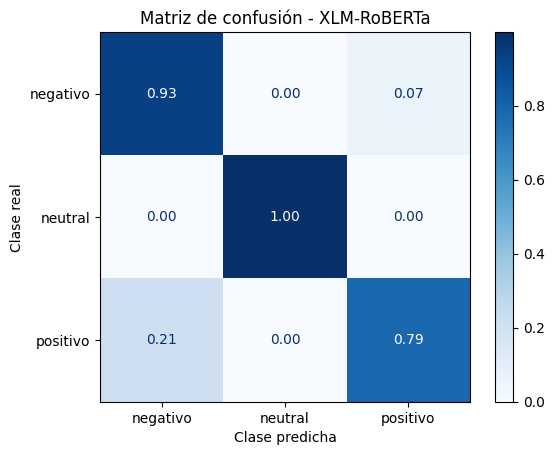

,accuracy,resenas
idioma,,
es_en,0.787879,33
fr,0.838095,210
pt_br,0.892704,233
en,0.901709,234
es,0.910247,1337


209 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
15549,es,positivo,negativo,"Lo compré hace un mes y lo estoy usando acá en casa casi todos los días. Trae garantía de seis meses, por si acaso. La portabilidad terminó siendo corriente a decir verdad, la verdad que no me movió de expectations..."
361,pt_br,negativo,positivo,"Comprei em meados do ano e tá no meu quarto desde então, uso quase todo dia, principalmente de manhã. Recomendo a qualidade de olhos fechados, sincermante. A demora do envio foi de mais ou menos uma semana até chegar na minha casa. Me arrependi de ter escolhido esse serviço, não teve jeito."
992,es,positivo,negativo,"Lo pedi hace poco en oferta y llego en unos cuatro dias a mi casa. La pantalla tactil me decepciono bastante, la verdad. Lo uso en la cocina de vez en cuando, nada del otro mundo. Eso si, el sonido fue todo un acierto."
19360,pt_br,negativo,positivo,"Comprei o relógio inteligente mês passado pra acompanhar os treinos na academia, meu filho foi quem me convenceu. A bateria dura quase uma semana inteira, digo, durou uma semana até eu tirar do carregador pela primeira vez. A tela responde rapidinho, respondia, até dar uma tela preta na quarta. Sábado lavei a louça com ele no pulso e nada aconteceu com a louça. A verdade é que ele virou parte da rotina da gaveta."
6442,pt_br,negativo,positivo,"Comprei isso no comecinho do mês pela internet, chegou em quatro dias na caixa lacrada. A duração da carga foi um erro de compra. Montei num sábado à tarde na sala seguindo o manual, não levei meia hora. Recomendo a montagem de olhos fechados."
7242,en,positivo,negativo,"I bought it mid-month because I needed one for the office. I'll get straight to the point. Every penny I paid for the material was worth it. Also, the interface gave me more than one headache. The shipping arrived in four days, in case anyone is wondering about that."
12796,en,negativo,positivo,"I bought it a couple of months ago to replace one I wasn't using anymore, and it arrived in about three days. The remote responded just as I expected, nothing more. It's got every feature under the sun, as you can see. As for the processor, I'd give it one star, honestly."
5455,es,positivo,negativo,"Compré esto en línea y me llegó en unos cinco días, en su caja tal cual. La uso en casa casi a diario desde que la recibí. La verdad no pare de tener problemas con el sonido desde el primer día que la prendí. Eso sí, la cámara me hizo la vida mas facil para lo que la necesito. Queda a criterio de cada uno, yo nomás cuento mi experiencia."
9835,es,positivo,negativo,"Compré este equipo a mediados de mes y llegó en tres días a mi casa. El procesador fue todo un acierto, la verdad que sin quejas en esa parte. Ahora, el cargador me decepcionó de lo lindo; no me lo esperaba. Lo estuve probando estos días junto con todo lo demás que venía en la caja."
243,es,positivo,negativo,"La pedí un martes y me llegó el jueves a la oficina. La batería venía cargada de fábrica así que la empecé a usar de una. He de decir que la autonomía se mantuvo durable para ser honesto. La uso nomás para lo del trabajo, nada fuera de lo común."


In [47]:
errores_xlm_roberta = identificar_errores(xlm_roberta.clases_test, test_df, "XLM-RoBERTa")

### 4.3 - XLM-RoBERTa ajustado para sentimiento en Twitter

`cardiffnlp/twitter-xlm-roberta-base-sentiment` es XLM-RoBERTa con un preentrenamiento adicional en unos 198 millones
de tuits multilingües, ajustado después para clasificar sentimiento en ocho idiomas, entre ellos español, inglés,
francés y portugués. Sus tres clases (*negative*, *neutral*, *positive*) están en el mismo orden que las nuestras, así
que se reutiliza su capa de clasificación ya entrenada (no aparece el aviso *MISSING*) y el *fine-tuning* parte de un
modelo que ya distingue sentimientos. La pregunta es si lo aprendido con tuits, que son textos cortos e informales,
sirve para reseñas de productos.

In [48]:
twitter = entrenar_transformer(
    "cardiffnlp/twitter-xlm-roberta-base-sentiment", "XLM-RoBERTa-Twitter"
)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (9 outputs left out)

Época 3/4: 100%|██████████| 1152/1152 [08:07<00:00,  2.36it/s]


loss = 0.1443, accuracy = 0.9198, val_loss = 0.1657, val_accuracy = 0.9013


Época 4/4: 100%|██████████| 1152/1152 [08:06<00:00,  2.37it/s]


loss = 0.1186, accuracy = 0.9347, val_loss = 0.1816, val_accuracy = 0.9003
Parada temprana en la época 4
Mejor época según val_loss: 3 (val_loss = 0.1657, val_accuracy = 0.9013)
Archivo guardado en ./datos/submission_XLM-RoBERTa-Twitter.csv (6781 predicciones)
answer
positivo    0.448459
negativo    0.361599
neutral     0.189942
Name: proportion, dtype: float64


In [49]:
print(open("./datos/submission_XLM-RoBERTa-Twitter.csv").read())

id,answer
0,positivo
1,neutral
2,negativo
3,neutral
4,negativo
5,positivo
6,negativo
7,positivo
8,negativo
9,negativo
10,neutral
11,negativo
12,positivo
13,positivo
14,positivo
15,positivo
16,positivo
17,negativo
18,negativo
19,negativo
20,neutral
21,positivo
22,neutral
23,negativo
24,positivo
25,negativo
26,positivo
27,neutral
28,negativo
29,negativo
30,positivo
31,positivo
32,negativo
33,neutral
34,negativo
35,positivo
36,negativo
37,positivo
38,positivo
39,negativo
40,positivo
41,positivo
42,neutral
43,negativo
44,negativo
45,positivo
46,neutral
47,negativo
48,positivo
49,positivo
50,positivo
51,positivo
52,positivo
53,positivo
54,negativo
55,neutral
56,neutral
57,positivo
58,positivo
59,positivo
60,negativo
61,negativo
62,neutral
63,positivo
64,negativo
65,positivo
66,positivo
67,negativo
68,positivo
69,positivo
70,positivo
71,negativo
72,positivo
73,positivo
74,neutral
75,negativo
76,negativo
77,negativo
78,neutral
79,positivo
80,negativo
81,neutral
82,neutral
83,neutral
84,positi

#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.

In [ ]:
errores_twitter = identificar_errores(twitter.clases_test, test_df, "XLM-RoBERTa-Twitter")

### 4.4 - Comparación de todos los modelos

Comparamos los tres transformers con todas las RNN usando `resumir_historiales`. Después contamos cuántas reseñas de
`test_df` falla cada transformer y cuántas de ellas también falla la mejor RNN (sección 3.3). Si todos los modelos
fallan casi las mismas reseñas, el problema probablemente está en esas reseñas (por ejemplo, etiquetas ambiguas) y no
en la arquitectura.

In [ ]:
transformers_entrenados = {
    "mBERT": mbert,
    "XLM-RoBERTa": xlm_roberta,
    "XLM-RoBERTa-Twitter": twitter,
}

pd.concat(
    [
        resumir_historiales(historiales),
        resumir_historiales(historiales_mejorados).assign(
            modelo=lambda d: d["modelo"] + " (mejorado)"
        ),
        resumir_historiales({n: r.historial for n, r in transformers_entrenados.items()}),
    ]
).sort_values("val_accuracy", ascending=False)

In [ ]:
# Índices de las reseñas de test_df mal clasificadas por cada modelo
fallas_rnn = set(errores_rnn.index)
fallas = {
    "mBERT": set(errores_mbert.index),
    "XLM-RoBERTa": set(errores_xlm_roberta.index),
    "XLM-RoBERTa-Twitter": set(errores_twitter.index),
}

print(f"La mejor RNN falla {len(fallas_rnn)} reseñas.")
print(f"Reseñas que fallan la mejor RNN y los tres transformers: {len(fallas_rnn.intersection(*fallas.values()))}")

pd.DataFrame(
    {
        "errores": {n: len(f) for n, f in fallas.items()},
        "también los falla la RNN": {n: len(f & fallas_rnn) for n, f in fallas.items()},
        "solo los falla el transformer": {n: len(f - fallas_rnn) for n, f in fallas.items()},
    }
)

## 4.5 - RoBERTa con la última oración explícita

In [ ]:
def tokenizar_con_ultima(textos, ultimas, tokenizador):
    """Tokeniza pares (última oración, reseña). El tokenizador los une como
    [CLS] última oración [SEP] reseña [SEP], así el modelo ve la última oración por separado."""
    return tokenizador(
        list(ultimas),
        list(textos),
        padding=True,
        truncation="only_second",  # si hiciera falta recortar, se recorta la reseña, no la última oración
        max_length=MAX_TOKENS,
        return_tensors="pt",
    )


def dataset_a_torch_con_ultima(df, shuffle, tokenizador, batch_size=16):
    """Igual que `dataset_a_torch`, pero cada ejemplo es el par (última oración, reseña)."""
    ejemplos = list(zip(df["text"], df["ultima"], df["label"].map(etiqueta_a_id)))

    def armar_lote(lote):
        textos, ultimas, ids = zip(*lote)
        entradas = tokenizar_con_ultima(textos, ultimas, tokenizador)
        entradas["labels"] = torch.tensor(ids)
        return entradas

    return DataLoader(
        ejemplos, batch_size=batch_size, shuffle=shuffle, collate_fn=armar_lote
    )


class PredictorTransformerConUltima(PredictorTransformer):
    """Como `PredictorTransformer`, pero recibe los lotes {"text", "ultima"} que arma
    `crear_archivo_predicciones` con `columnas=columnas_2`."""

    @torch.no_grad()
    def predict(self, lotes):
        self.model.eval()
        logits = []
        for lote in lotes:
            textos = [t.decode("utf-8") for t in lote["text"].numpy()]
            ultimas = [t.decode("utf-8") for t in lote["ultima"].numpy()]
            entradas = tokenizar_con_ultima(textos, ultimas, self.tokenizador).to(dispositivo)
            logits.append(self.model(**entradas).logits.cpu())
        return torch.cat(logits).numpy()


def entrenar_transformer_con_ultima(nombre_modelo, nombre_corto, **parametros_entrenamiento):
    """Igual que `entrenar_transformer`, pero el modelo recibe la última oración como entrada aparte."""
    tokenizador, model = cargar_transformer(nombre_modelo)
    historial = entrenar_transformer_con_parada_temprana(
        model,
        dataset_a_torch_con_ultima(train_df, shuffle=True, tokenizador=tokenizador),
        dataset_a_torch_con_ultima(test_df, shuffle=False, tokenizador=tokenizador),
        **parametros_entrenamiento,
    )

    predictor = PredictorTransformerConUltima(model, tokenizador)
    crear_archivo_predicciones(
        predictor, dataset_eval, f"./datos/submission_{nombre_corto}.csv", columnas=columnas_2
    )

    lotes_test = tf.data.Dataset.from_tensor_slices(entradas_modelo(test_df, columnas_2)).batch(32)
    clases_test = predictor.predict(lotes_test).argmax(axis=1)

    model.to("cpu")
    liberar_memoria_gpu()
    return SimpleNamespace(
        model=model, tokenizador=tokenizador, historial=historial, clases_test=clases_test
    )


In [ ]:
twitter_ultima = entrenar_transformer_con_ultima(
    "xlm-roberta-base", "XLM-RoBERTa-Twitter_ultima"
)


#### Identificación del error

In [ ]:
errores_twitter_ultima = identificar_errores(
    twitter_ultima.clases_test, test_df, "XLM-RoBERTa + última oración"
)

# Comparación con el mismo modelo sin la última oración
resumir_historiales(
    {
        "XLM-RoBERTa-Twitter": twitter.historial,
        "XLM-RoBERTa-Twitter + última oración": twitter_ultima.historial,
    }
)
